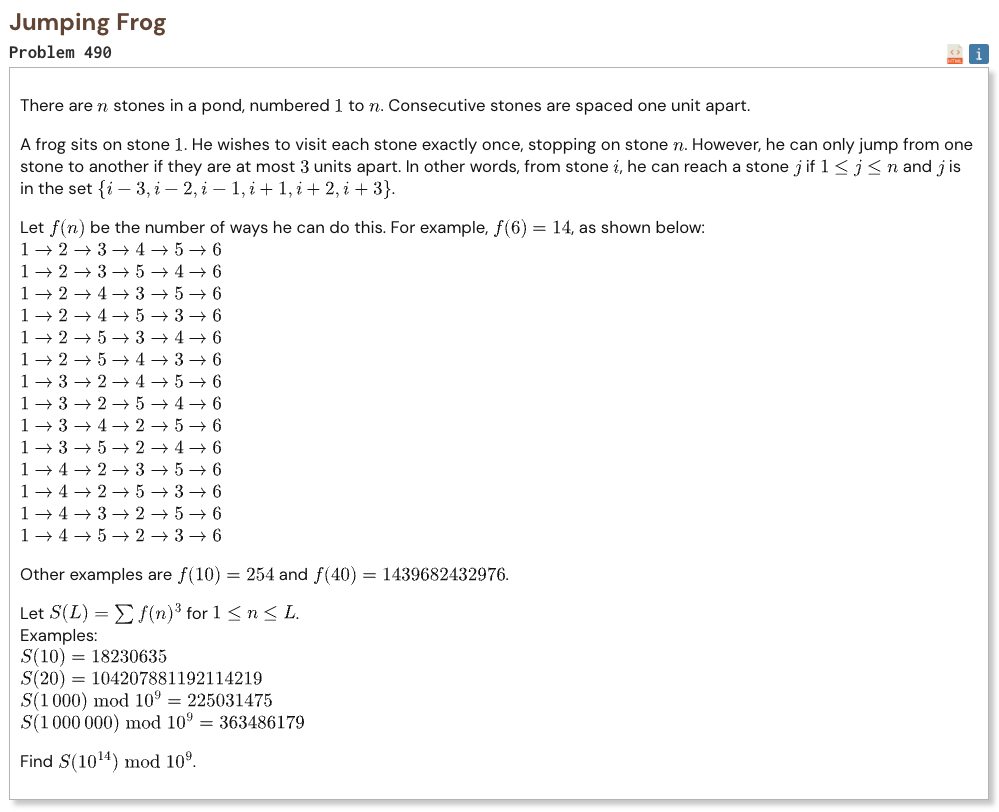

## Initial approach

- first find a linear recurrence for the number of valid frog routes
- cube this sequence indirectly by working with the roots of its recurrence
- the cubed sequence also satisfies a linear recurrence, with order 120
- build that recurrence exactly using power sums and Newton identities
- convert it into a recurrence for the cumulative sum
- use fast polynomial exponentiation to jump directly to position 10 to the power 14
- keep every final calculation modulo 10 to the power 9

In [1]:
%%time

MOD = 10**9
N = 10**14

route_rec = [2, -1, 2, 1, 1, 0, -1, -1]
characteristic = [1, -2, 1, -2, -1, -1, 0, 1, 1]

degree = 120
root_count = 8

power_sums = [0] * (3 * degree + 1)
power_sums[0] = root_count

coefficients = characteristic[1:]

for m in range(1, 3 * degree + 1):
    if m <= root_count:
        value = sum(
            coefficients[j - 1] * power_sums[m - j]
            for j in range(1, m)
        )
        value += m * coefficients[m - 1]
    else:
        value = sum(
            coefficients[j - 1] * power_sums[m - j]
            for j in range(1, root_count + 1)
        )

    power_sums[m] = -value

cube_power_sums = [0] * (degree + 1)

for m in range(1, degree + 1):
    p1 = power_sums[m]
    p2 = power_sums[2 * m]
    p3 = power_sums[3 * m]

    cube_power_sums[m] = (
        p1**3 + 3 * p1 * p2 + 2 * p3
    ) // 6

cube_characteristic = [1]

for k in range(1, degree + 1):
    value = sum(
        cube_characteristic[k - i] * cube_power_sums[i]
        for i in range(1, k + 1)
    )

    cube_characteristic.append(-value // k)

sum_characteristic = [0] * (degree + 2)
sum_characteristic[0] = 1

for i in range(1, degree + 1):
    sum_characteristic[i] = (
        cube_characteristic[i]
        - cube_characteristic[i - 1]
    )

sum_characteristic[-1] = -cube_characteristic[-1]

sum_rec = [
    (-sum_characteristic[i]) % MOD
    for i in range(1, degree + 2)
]

f = [0, 1, 1, 1, 2, 6, 14, 28, 56]

for n in range(9, degree + 2):
    value = sum(
        route_rec[j - 1] * f[n - j]
        for j in range(1, 9)
    )
    f.append(value)

initial = [0] * (degree + 1)
running = 0

for n in range(1, degree + 1):
    running = (running + f[n]**3) % MOD
    initial[n] = running

def combine(a, b):
    k = len(sum_rec)
    temp = [0] * (2 * k - 1)

    for i, x in enumerate(a):
        if x == 0:
            continue

        for j, y in enumerate(b):
            if y:
                temp[i + j] = (
                    temp[i + j] + x * y
                ) % MOD

    for d in range(2 * k - 2, k - 1, -1):
        value = temp[d]

        if value == 0:
            continue

        for j in range(1, k + 1):
            temp[d - j] = (
                temp[d - j]
                + value * sum_rec[j - 1]
            ) % MOD

    return temp[:k]

def recurrence_value(n):
    k = len(sum_rec)

    if n < k:
        return initial[n]

    result = [1] + [0] * (k - 1)
    base = [0, 1] + [0] * (k - 2)

    while n:
        if n & 1:
            result = combine(result, base)

        base = combine(base, base)
        n //= 2

    return sum(
        result[i] * initial[i]
        for i in range(k)
    ) % MOD

result = recurrence_value(N)

print("Result:", result)

Result: 777577686
CPU times: user 123 ms, sys: 208 μs, total: 123 ms
Wall time: 123 ms
